In [3]:
#Load Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split

In [4]:
#Zip File
import zipfile

with zipfile.ZipFile('/content/dataset.zip.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/dataset')

In [5]:
#Verify whether folders imported
import os

print(os.listdir('/content/dataset'))

['test', 'train']


In [6]:
class_names = ['cats', 'dogs']

In [7]:
#Load Train and Test Data
train_dir = '/content/dataset/train'
test_dir = '/content/dataset/test'

train_data = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(128, 128),
    batch_size=32
)

test_data = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(128, 128),
    batch_size=32
)

Found 557 files belonging to 2 classes.
Found 140 files belonging to 2 classes.


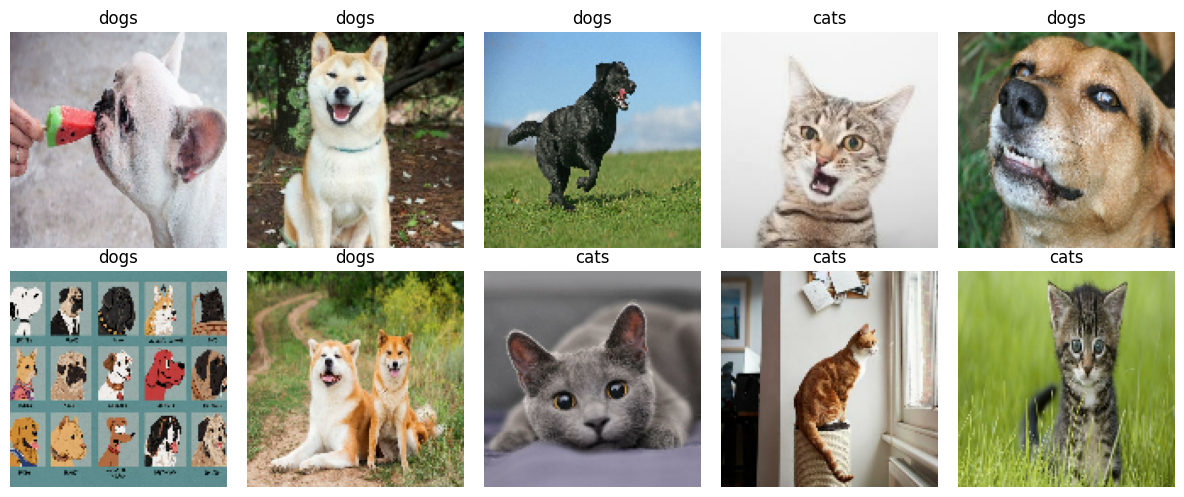

In [8]:
#See Images
plt.figure(figsize=(12, 5))

for images, labels in train_data.take(1):
    for i in range(10):
        plt.subplot(2, 5, i+1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [9]:
#Make Model
model = keras.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.Rescaling(1./255),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid")
])

In [10]:
#Compile
model.compile(optimizer="adam",loss="binary_crossentropy",metrics=["accuracy"])

In [11]:
#Fit Model
history = model.fit(
    train_data,
    epochs=20,
    validation_data=test_data
)

Epoch 1/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 29s 2s/step - accuracy: 0.4937 - loss: 0.7332 - val_accuracy: 0.5357 - val_loss: 0.6917
Epoch 2/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 25s 1s/step - accuracy: 0.5224 - loss: 0.6902 - val_accuracy: 0.5214 - val_loss: 0.6908
Epoch 3/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 41s 1s/step - accuracy: 0.5566 - loss: 0.6756 - val_accuracy: 0.5143 - val_loss: 0.6971
Epoch 4/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 26s 1s/step - accuracy: 0.4919 - loss: 0.6968 - val_accuracy: 0.5286 - val_loss: 0.6923
Epoch 5/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 23s 1s/step - accuracy: 0.5242 - loss: 0.6900 - val_accuracy: 0.5786 - val_loss: 0.6917
Epoch 6/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 42s 1s/step - accuracy: 0.5853 - loss: 0.6707 - val_accuracy: 0.5500 - val_loss: 0.6861
Epoch 7/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.6338 - loss: 0.6505 - val_accuracy: 0.6214 - val_loss: 0.7071
Epoch 8/20
18/18 ━━━━━━━━━━━━━━━━━━━━ 25s 1s/step - accuracy: 0.6014 - loss: 0.6495 - val_accuracy: 0.5929 - val_loss:

In [12]:
#Evaluate
test_loss, test_accuracy = model.evaluate(test_data)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 231ms/step - accuracy: 0.5714 - loss: 0.7567
Test Accuracy: 0.5714285969734192
Test Loss: 0.7567343711853027


In [13]:
#Sigmoid Predictions
predictions = model.predict(test_data.take(1))
print(predictions[:5])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 458ms/step
[[0.32198733]
 [0.9985242 ]
 [0.719904  ]
 [0.25906923]
 [0.88346   ]]


In [14]:
#Actual Predictions
for images, labels in test_data.take(1):
    predictions = model.predict(images)

    for i in range(5):
        predicted_class = 1 if predictions[i][0] >= 0.5 else 0
        actual_class = labels[i].numpy()

        print("Predicted:", class_names[predicted_class])
        print("Actual:", class_names[actual_class])
        print("----------------")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 362ms/step
Predicted: cats
Actual: dogs
----------------
Predicted: dogs
Actual: dogs
----------------
Predicted: dogs
Actual: dogs
----------------
Predicted: dogs
Actual: cats
----------------
Predicted: cats
Actual: cats
----------------
